In [1]:
import importlib
for pkg in ["numpy", "pandas", "matplotlib", "scipy", "uproot", "awkward"]:
    try:
        m = importlib.import_module(pkg)
        print(f"OK       {pkg:12s} {m.__version__}")
    except ImportError:
        print(f"MISSING  {pkg}")

OK       numpy        2.1.3
OK       pandas       2.2.3
OK       matplotlib   3.10.0
OK       scipy        1.16.3
MISSING  uproot
MISSING  awkward


In [2]:
!pip install -q uproot awkward fsspec-xrootd

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 441.2/441.2 kB 3.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.0/1.0 MB 13.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 698.7/698.7 kB 29.7 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 8.9/8.9 MB 7.6 MB/s eta 0:00:00


In [3]:
import uproot
import awkward as ak
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import scipy
print("uproot", uproot.__version__, "| awkward", ak.__version__)

uproot 5.7.7 | awkward 2.14.0


In [4]:
URL = "root://eospublic.cern.ch//eos/root-eos/cms_opendata_2012_nanoaod/Run2012B_DoubleMuParked.root"
f = uproot.open(URL)
print(f)

<ReadOnlyDirectory '/' at 0x792fe5a842f0>


In [5]:
print(f.keys())                      # top-level objects in the file
tree = f["Events"]                   # the main table of events
print("Events:  ", tree.num_entries) # number of events
print("Branches:", len(tree.keys()))  # number of columns

muon_branches = [b for b in tree.keys() if b.startswith("Muon_") or b == "nMuon"]
print(len(muon_branches), "muon branches:")
for b in muon_branches:
    print("  ", b, "|", tree[b].typename)

['Events;1']
Events:   29308627
Branches: 32
14 muon branches:
   nMuon | uint32_t
   Muon_pt | float[]
   Muon_eta | float[]
   Muon_phi | float[]
   Muon_mass | float[]
   Muon_charge | int32_t[]
   Muon_pfRelIso03_all | float[]
   Muon_pfRelIso04_all | float[]
   Muon_tightId | bool[]
   Muon_softId | bool[]
   Muon_dxy | float[]
   Muon_dxyErr | float[]
   Muon_dz | float[]
   Muon_dzErr | float[]


In [6]:
branches = ["nMuon", "Muon_pt", "Muon_eta", "Muon_phi", "Muon_mass", "Muon_charge"]
events = tree.arrays(branches, entry_stop=10_000)   # only first 10k events
print(events.type)
print(events[:5].tolist())   # first 5 events as plain Python

10000 * {nMuon: uint32, Muon_pt: var * float32, Muon_eta: var * float32, Muon_phi: var * float32, Muon_mass: var * float32, Muon_charge: var * int32}
[{'nMuon': 2, 'Muon_pt': [52.00833511352539, 42.85704040527344], 'Muon_eta': [1.2523202896118164, 1.6531223058700562], 'Muon_phi': [0.8424168229103088, -2.154824733734131], 'Muon_mass': [0.10565836727619171, 0.10565836727619171], 'Muon_charge': [1, -1]}, {'nMuon': 1, 'Muon_pt': [5.019948482513428], 'Muon_eta': [2.1219534873962402], 'Muon_phi': [1.7212640047073364], 'Muon_mass': [0.10565836727619171], 'Muon_charge': [1]}, {'nMuon': 2, 'Muon_pt': [15.967432022094727, 12.481289863586426], 'Muon_eta': [-1.241450548171997, -0.7956085205078125], 'Muon_phi': [-2.8183231353759766, -1.5160582065582275], 'Muon_mass': [0.10565836727619171, 0.10565836727619171], 'Muon_charge': [-1, 1]}, {'nMuon': 2, 'Muon_pt': [53.42825698852539, 38.43761444091797], 'Muon_eta': [-1.942970871925354, -0.9862729907035828], 'Muon_phi': [2.087547779083252, -0.992049276828

In [7]:
pt = events["Muon_pt"]
print(pt[0], pt[1], pt[2])        # different lengths
print(ak.num(pt)[:10])            # muons per event (should match nMuon)
print((pt > 20)[:5])              # elementwise comparison, still jagged
print(pt[pt > 20][:5])            # mask keeps only passing muons
print(ak.sum(pt > 20, axis=1)[:10])   # count of passing muons per event
print(len(ak.flatten(pt)))        # total muons in the sample

[52, 42.9] [5.02] [16, 12.5]
[2, 1, 2, 2, 2, 2, 2, 2, 2, 2]
[[True, True], [False], [False, False], [True, True], [False, False]]
[[52, 42.9], [], [], [53.4, 38.4], []]
[2, 0, 0, 2, 0, 2, 0, 1, 2, 2]
23424


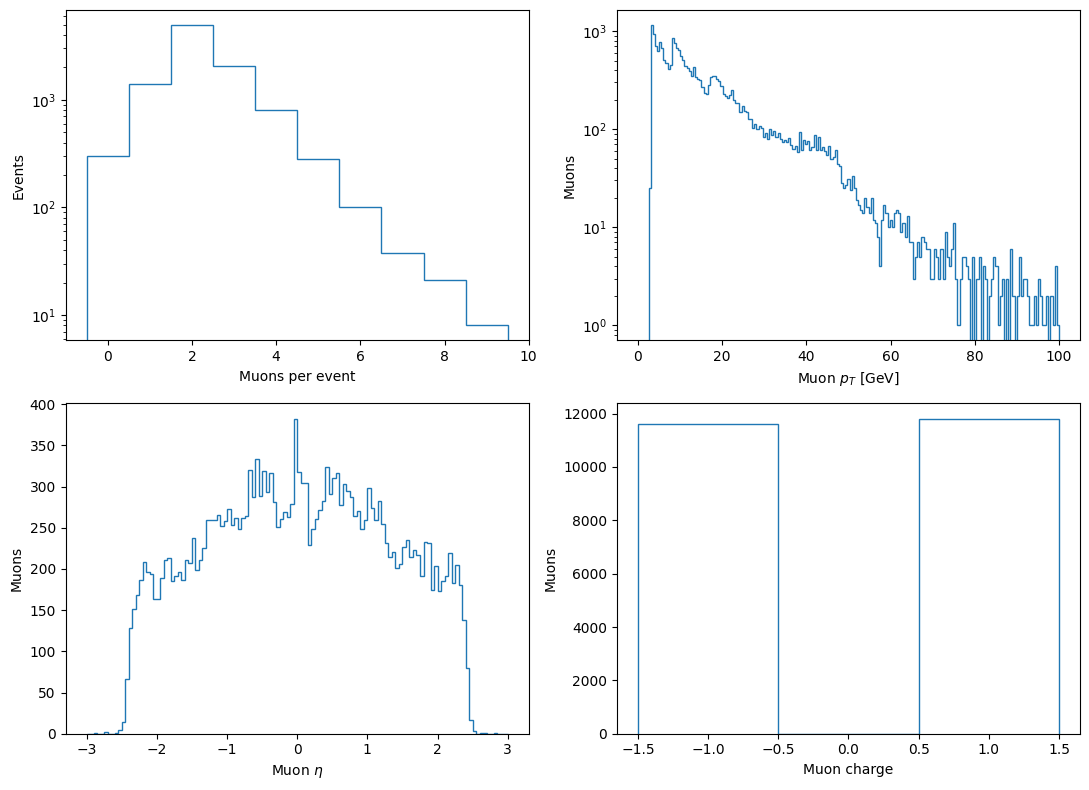

In [8]:
fig, ax = plt.subplots(2, 2, figsize=(11, 8))

# 1. multiplicity
ax[0,0].hist(ak.to_numpy(events["nMuon"]), bins=np.arange(-0.5, 10.5, 1), histtype="step")
ax[0,0].set(xlabel="Muons per event", ylabel="Events", yscale="log")

# 2. pT
ax[0,1].hist(ak.to_numpy(ak.flatten(events["Muon_pt"])), bins=np.linspace(0, 100, 200), histtype="step")
ax[0,1].set(xlabel=r"Muon $p_T$ [GeV]", ylabel="Muons", yscale="log")

# 3. eta
ax[1,0].hist(ak.to_numpy(ak.flatten(events["Muon_eta"])), bins=np.linspace(-3, 3, 121), histtype="step")
ax[1,0].set(xlabel=r"Muon $\eta$", ylabel="Muons")

# 4. charge
ax[1,1].hist(ak.to_numpy(ak.flatten(events["Muon_charge"])), bins=[-1.5, -0.5, 0.5, 1.5], histtype="step")
ax[1,1].set(xlabel="Muon charge", ylabel="Muons")

plt.tight_layout()
plt.savefig("day1_basic_muon_plots.png", dpi=200)
plt.show()